In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')

In [13]:
df=pd.read_csv("LoanData.csv")

In [14]:
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [9]:
df.shape

(614, 13)

In [10]:
df.columns.tolist()

['Loan_ID',
 'Gender',
 'Married',
 'Dependents',
 'Education',
 'Self_Employed',
 'ApplicantIncome',
 'CoapplicantIncome',
 'LoanAmount',
 'Loan_Amount_Term',
 'Credit_History',
 'Property_Area',
 'Loan_Status']

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [13]:
df["Loan_ID"].unique()

array(['LP001002', 'LP001003', 'LP001005', 'LP001006', 'LP001008',
       'LP001011', 'LP001013', 'LP001014', 'LP001018', 'LP001020',
       'LP001024', 'LP001027', 'LP001028', 'LP001029', 'LP001030',
       'LP001032', 'LP001034', 'LP001036', 'LP001038', 'LP001041',
       'LP001043', 'LP001046', 'LP001047', 'LP001050', 'LP001052',
       'LP001066', 'LP001068', 'LP001073', 'LP001086', 'LP001087',
       'LP001091', 'LP001095', 'LP001097', 'LP001098', 'LP001100',
       'LP001106', 'LP001109', 'LP001112', 'LP001114', 'LP001116',
       'LP001119', 'LP001120', 'LP001123', 'LP001131', 'LP001136',
       'LP001137', 'LP001138', 'LP001144', 'LP001146', 'LP001151',
       'LP001155', 'LP001157', 'LP001164', 'LP001179', 'LP001186',
       'LP001194', 'LP001195', 'LP001197', 'LP001198', 'LP001199',
       'LP001205', 'LP001206', 'LP001207', 'LP001213', 'LP001222',
       'LP001225', 'LP001228', 'LP001233', 'LP001238', 'LP001241',
       'LP001243', 'LP001245', 'LP001248', 'LP001250', 'LP0012

In [14]:
df["Gender"].unique()

array(['Male', 'Female', nan], dtype=object)

In [15]:
df["Married"].unique()

array(['No', 'Yes', nan], dtype=object)

In [16]:
df["Dependents"].unique()

array(['0', '1', '2', '3+', nan], dtype=object)

In [17]:
df["Education"].unique()

array(['Graduate', 'Not Graduate'], dtype=object)

In [18]:
df["Self_Employed"].unique()

array(['No', 'Yes', nan], dtype=object)

In [20]:
df["ApplicantIncome"].nunique()

505

In [21]:
df["CoapplicantIncome"] = df["CoapplicantIncome"].astype(int)
df["CoapplicantIncome"].nunique()

287

In [22]:
df["LoanAmount"].nunique()

203

In [23]:
df["Loan_Amount_Term"].unique()

array([360., 120., 240.,  nan, 180.,  60., 300., 480.,  36.,  84.,  12.])

In [24]:
df["Loan_Amount_Term"].value_counts()

Loan_Amount_Term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64

In [25]:
df["Credit_History"].unique()

array([ 1.,  0., nan])

In [28]:
df["Credit_History"] = df["Credit_History"].replace({1:"Yes",0:"No"})
df["Credit_History"].value_counts()

Credit_History
Yes    475
No      89
Name: count, dtype: int64

In [29]:
df["Property_Area"].unique()

array(['Urban', 'Rural', 'Semiurban'], dtype=object)

In [30]:
df["Loan_Status"].unique()

array(['Y', 'N'], dtype=object)

In [32]:
df["Loan_Status"].value_counts()

Loan_Status
Y    422
N    192
Name: count, dtype: int64

In [25]:
df["overall_income"] = df['ApplicantIncome'] + df['CoapplicantIncome']
df.drop(columns=['ApplicantIncome','CoapplicantIncome'], inplace=True)
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,overall_income
1,LP001003,Male,Yes,1,Graduate,No,128.0,360.0,1.0,Rural,N,6091.0
2,LP001005,Male,Yes,0,Graduate,Yes,66.0,360.0,1.0,Urban,Y,3000.0
3,LP001006,Male,Yes,0,Not Graduate,No,120.0,360.0,1.0,Urban,Y,4941.0
4,LP001008,Male,No,0,Graduate,No,141.0,360.0,1.0,Urban,Y,6000.0
5,LP001011,Male,Yes,2,Graduate,Yes,267.0,360.0,1.0,Urban,Y,9613.0
...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,71.0,360.0,1.0,Rural,Y,2900.0
610,LP002979,Male,Yes,3+,Graduate,No,40.0,180.0,1.0,Rural,Y,4106.0
611,LP002983,Male,Yes,1,Graduate,No,253.0,360.0,1.0,Urban,Y,8312.0
612,LP002984,Male,Yes,2,Graduate,No,187.0,360.0,1.0,Urban,Y,7583.0


In [34]:
continous = ['overall_income','LoanAmount']
count = ['Dependents','Loan_Amount_Term']
categorical = ['Gender','Married','Education','Self_Employed','Credit_History','Property_Area', 'Loan_Status']

In [35]:
df[categorical].describe()

,Gender,Married,Education,Self_Employed,Credit_History,Property_Area,Loan_Status
count,601,611,614,582,564,614,614
unique,2,2,2,2,2,3,2
top,Male,Yes,Graduate,No,Yes,Semiurban,Y
freq,489,398,480,500,475,233,422


In [36]:
df[continous].describe()

,overall_income,LoanAmount
count,614.000000,592.000000
mean,7024.703583,146.412162
std,6458.664751,85.587325
min,1442.000000,9.000000
25%,4166.000000,100.000000
50%,5416.500000,128.000000
75%,7521.750000,168.000000
max,81000.000000,700.000000


In [37]:
df.isnull().sum()

Loan_ID              0
Gender              13
Married              3
Dependents          15
Education            0
Self_Employed       32
LoanAmount          22
Loan_Amount_Term    14
Credit_History      50
Property_Area        0
Loan_Status          0
overall_income       0
dtype: int64

<Axes: ylabel='overall_income'>

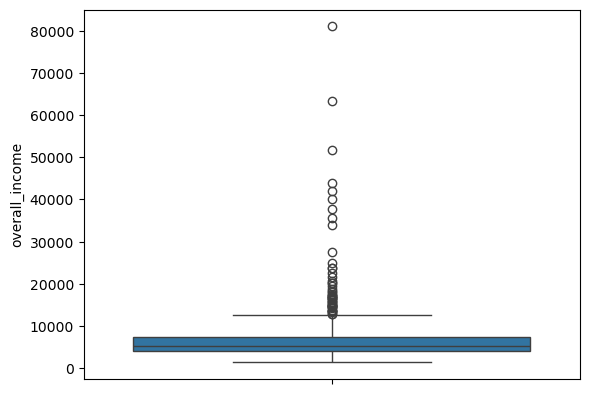

In [38]:
sns.boxplot(df["overall_income"])

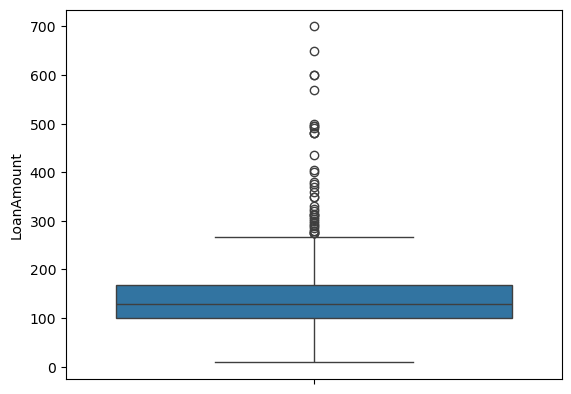

In [39]:
sns.boxplot(df["LoanAmount"])
plt.show()

In [40]:
df[continous].skew()

overall_income    5.633447
LoanAmount        2.677552
dtype: float64

In [41]:
df.duplicated().sum()

np.int64(0)

In [42]:
df["Dependents"] = df["Dependents"].replace({"3+":3})

In [24]:
#treat missing values

df["Gender"] = df["Gender"].fillna(df["Gender"].mode()) #fillna - filling null values || mode - most repeted values
df["Married"] = df["Married"].fillna(df["Married"].mode())
df = df.dropna() #delete the null values
df

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [45]:
#treat wrong data type

df["Dependents"] = df["Dependents"].astype(int)
df["Loan_Amount_Term"] = df["Loan_Amount_Term"].astype(int)

C:\Users\user\AppData\Local\Temp\ipykernel_14372\2391368227.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Dependents"] = df["Dependents"].astype(int)
C:\Users\user\AppData\Local\Temp\ipykernel_14372\2391368227.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Loan_Amount_Term"] = df["Loan_Amount_Term"].astype(int)


In [23]:
#treat the outliers

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [47]:
df["Gender"].value_counts()

Gender
Male      394
Female     86
Name: count, dtype: int64

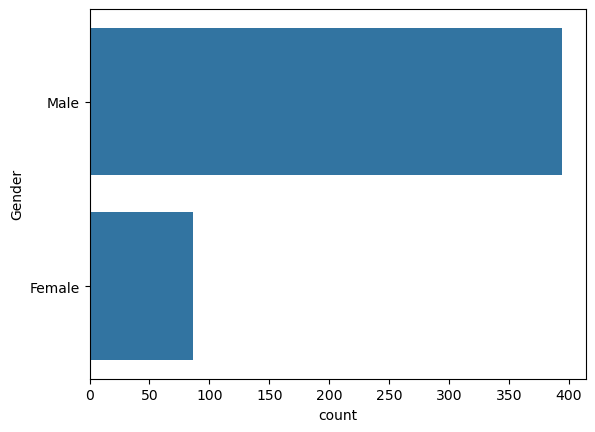

In [52]:
sns.countplot(df["Gender"])
plt.show()

In [53]:
df["Gender"].value_counts()/len(df)

Gender
Male      0.820833
Female    0.179167
Name: count, dtype: float64

In [54]:
df["Education"].value_counts()

Education
Graduate        383
Not Graduate     97
Name: count, dtype: int64

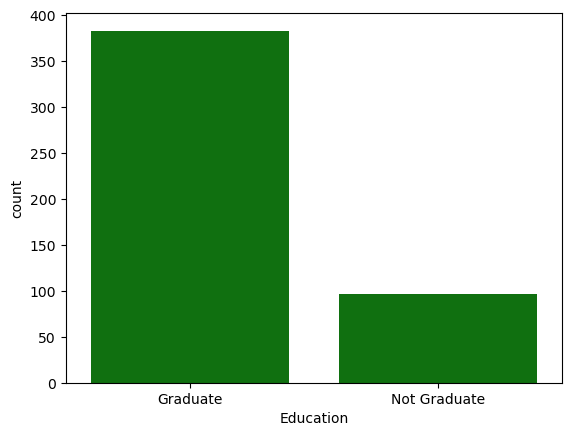

In [58]:
sns.countplot(x=df["Education"],color='green')
plt.show()

In [59]:
df["Education"].value_counts(normalize=True)

Education
Graduate        0.797917
Not Graduate    0.202083
Name: proportion, dtype: float64

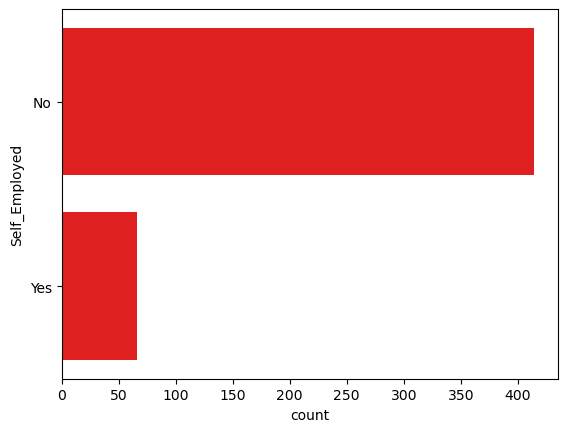

In [61]:
sns.countplot(df["Self_Employed"],stat='count',color="red")
plt.show()

In [62]:
df['Self_Employed'].value_counts()

Self_Employed
No     414
Yes     66
Name: count, dtype: int64

In [63]:
df["Dependents"].value_counts()

Dependents
0    274
2     85
1     80
3     41
Name: count, dtype: int64

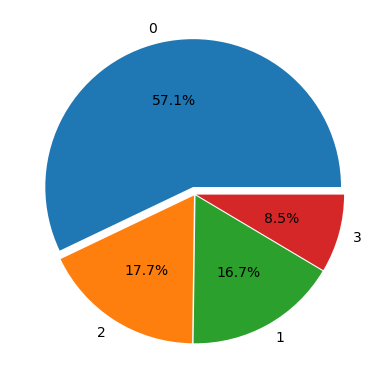

In [65]:
plt.pie(df["Dependents"].value_counts(),labels=[0,2,1,3],autopct="%0.1f%%",explode=[0.05,0.01,0.01,0.01])
plt.show()

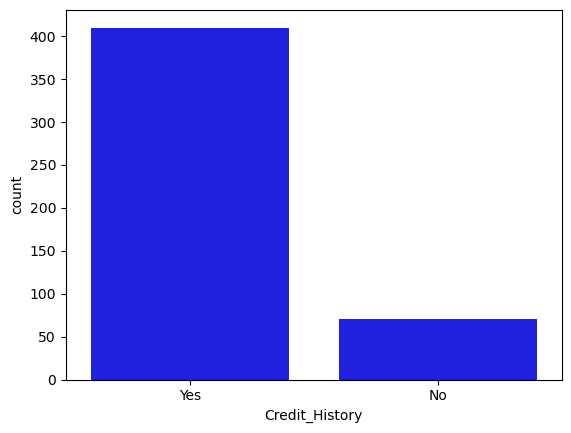

In [67]:
sns.countplot(x=df["Credit_History"],color="blue")
plt.show()

In [68]:
df['Credit_History'].value_counts()

Credit_History
Yes    410
No      70
Name: count, dtype: int64

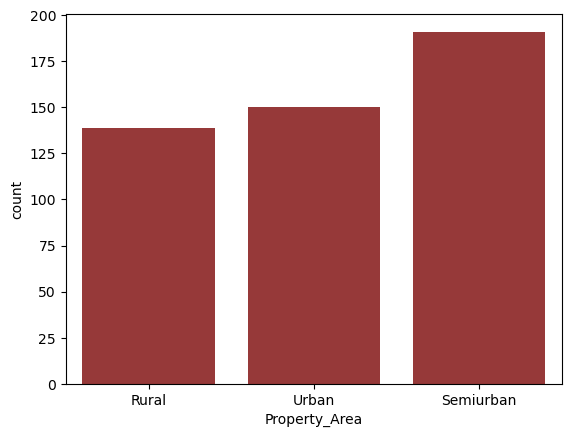

In [70]:
sns.countplot(x=df["Property_Area"],color="brown")
plt.show()

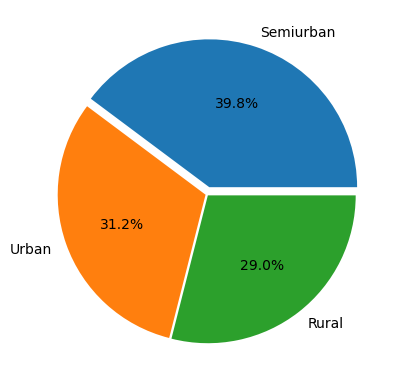

In [99]:
plt.pie(df["Property_Area"].value_counts(),labels=['Semiurban', 'Urban', 'Rural'],autopct="%0.1f%%",explode=[0.05,0.01,0.01])
plt.show()

In [71]:
df["Property_Area"].value_counts()

Property_Area
Semiurban    191
Urban        150
Rural        139
Name: count, dtype: int64

<Axes: xlabel='LoanAmount', ylabel='Count'>

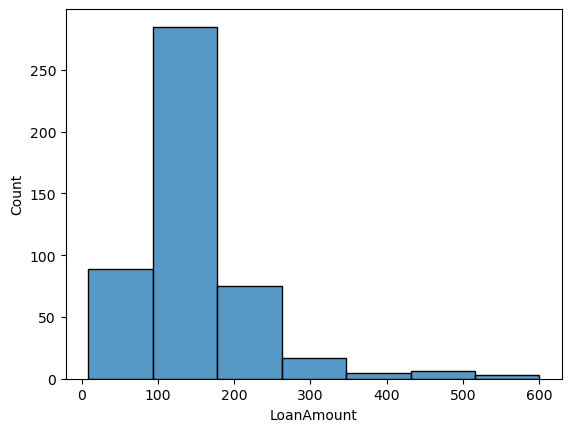

In [78]:
sns.histplot(df['LoanAmount'],bins=7)

In [79]:
df['LoanAmount'].describe()

count    480.000000
mean     144.735417
std       80.508164
min        9.000000
25%      100.000000
50%      128.000000
75%      170.000000
max      600.000000
Name: LoanAmount, dtype: float64

In [80]:
df['LoanAmount'].skew()

np.float64(2.3614368477871213)

<Axes: xlabel='LoanAmount', ylabel='Density'>

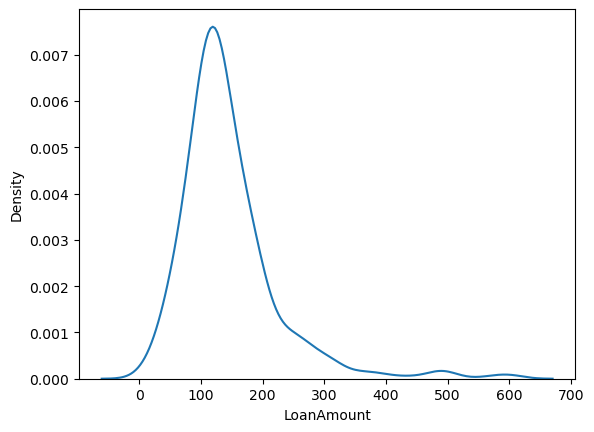

In [86]:
sns.kdeplot(df['LoanAmount'])

<Axes: xlabel='overall_income', ylabel='Count'>

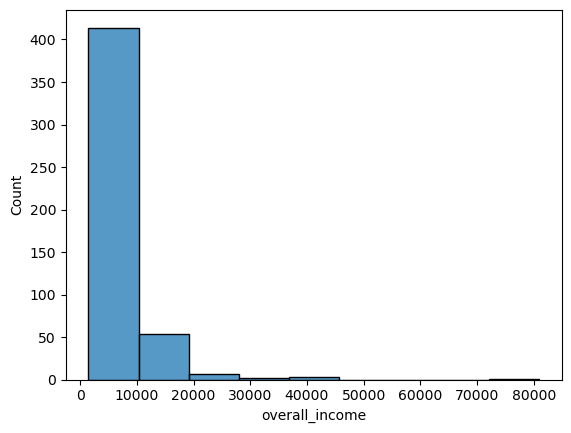

In [87]:
sns.histplot(df['overall_income'],bins=9)

In [90]:
df['overall_income'].describe()

count      480.000000
mean      6945.322917
std       5969.949565
min       1442.000000
25%       4148.000000
50%       5422.500000
75%       7672.500000
max      81000.000000
Name: overall_income, dtype: float64

In [91]:
df['overall_income'].skew()

np.float64(5.931353867991847)

<Axes: xlabel='overall_income', ylabel='Density'>

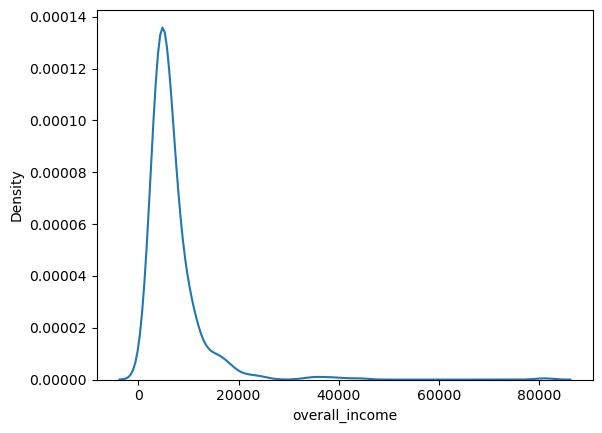

In [92]:
sns.kdeplot(df['overall_income'])

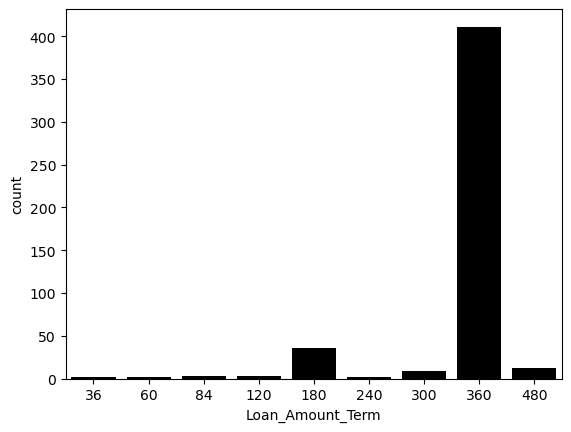

In [95]:
sns.countplot(x=df["Loan_Amount_Term"],color="black")
plt.show()

In [96]:
df['Loan_Amount_Term'].value_counts()

Loan_Amount_Term
360    411
180     36
480     12
300      9
120      3
84       3
60       2
240      2
36       2
Name: count, dtype: int64

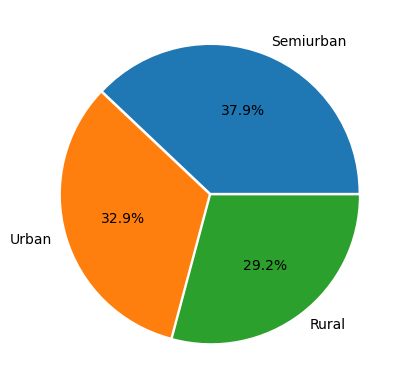

In [15]:
plt.pie(df["Property_Area"].value_counts(),labels=['Semiurban', 'Urban', 'Rural']
,autopct="%0.1f%%",explode=[0.01,0.01,0.01])
plt.show()

In [16]:
df['Property_Area'].value_counts()

Property_Area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64

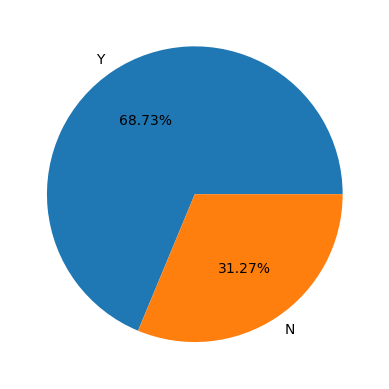

In [17]:
plt.pie(df["Loan_Status"].value_counts(),labels=['Y','N']
,autopct="%0.2f%%")
plt.show()

In [18]:
df["Loan_Status"].value_counts()

Loan_Status
Y    422
N    192
Name: count, dtype: int64

<Axes: xlabel='Loan_Status', ylabel='LoanAmount'>

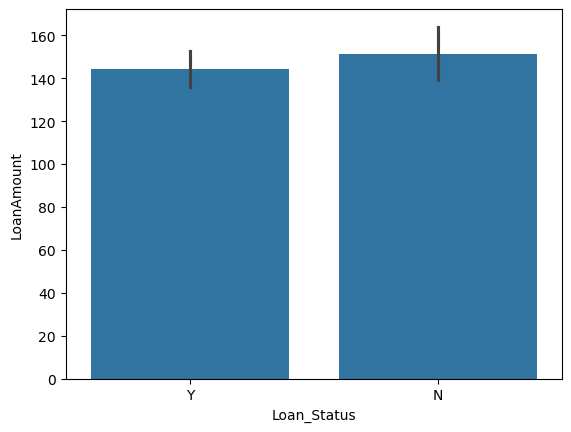

In [19]:
sns.barplot(x=df["Loan_Status"],y=df['LoanAmount'])

In [20]:
df.groupby("Loan_Status")["LoanAmount"].describe().T

Loan_Status,N,Y
count,181.000000,411.000000
mean,151.220994,144.294404
std,85.862783,85.484607
min,9.000000,17.000000
25%,100.000000,100.000000
50%,129.000000,126.000000
75%,176.000000,161.000000
max,570.000000,700.000000


In [26]:
df.groupby("Loan_Status")["overall_income"].describe().T

Loan_Status,N,Y
count,148.000000,332.000000
mean,7503.270270,6696.602169
std,8140.408997,4684.597263
min,1442.000000,1963.000000
25%,3985.250000,4164.500000
50%,5318.000000,5439.000000
75%,7777.250000,7550.250000
max,81000.000000,43897.000000


<Axes: xlabel='Loan_Status', ylabel='LoanAmount'>

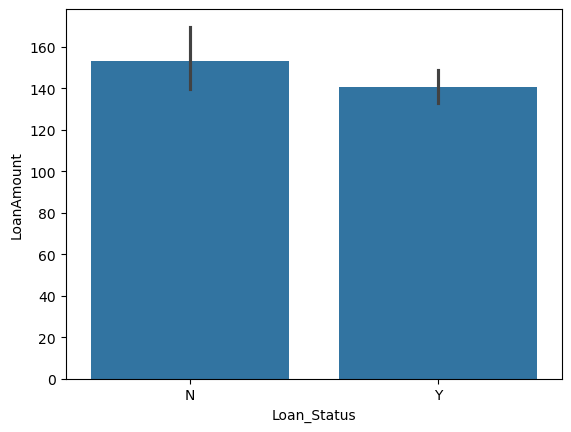

In [27]:
sns.barplot(x=df["Loan_Status"],y=df['LoanAmount'])

In [28]:
pd.crosstab(df["Gender"],df["Loan_Status"],margins=True)

Loan_Status,N,Y,All
Gender,,,
Female,32,54,86
Male,116,278,394
All,148,332,480


In [29]:
pd.crosstab(df["Education"],df["Loan_Status"],margins=True)

Loan_Status,N,Y,All
Education,,,
Graduate,112,271,383
Not Graduate,36,61,97
All,148,332,480


In [30]:
pd.crosstab(df["Dependents"],df["Loan_Status"],margins=True)

Loan_Status,N,Y,All
Dependents,,,
0,87,187,274
1,28,52,80
2,20,65,85
3+,13,28,41
All,148,332,480


In [31]:
pd.crosstab(df["Self_Employed"],df["Loan_Status"],margins=True,normalize=True)

Loan_Status,N,Y,All
Self_Employed,,,
No,0.260417,0.602083,0.8625
Yes,0.047917,0.089583,0.1375
All,0.308333,0.691667,1.0000


In [32]:
pd.crosstab(df["Loan_Amount_Term"],df["Loan_Status"],margins=True,normalize=True)

Loan_Status,N,Y,All
Loan_Amount_Term,,,
36.0,0.004167,0.000000,0.004167
60.0,0.000000,0.004167,0.004167
84.0,0.002083,0.004167,0.006250
120.0,0.000000,0.006250,0.006250
180.0,0.025000,0.050000,0.075000
240.0,0.002083,0.002083,0.004167
300.0,0.010417,0.008333,0.018750
360.0,0.247917,0.608333,0.856250
480.0,0.016667,0.008333,0.025000


In [33]:
pd.crosstab(df["Credit_History"],df["Loan_Status"],margins=True,normalize=True)

Loan_Status,N,Y,All
Credit_History,,,
0.0,0.131250,0.014583,0.145833
1.0,0.177083,0.677083,0.854167
All,0.308333,0.691667,1.000000


In [34]:
pd.crosstab(df["Property_Area"],df["Loan_Status"],margins=True)

Loan_Status,N,Y,All
Property_Area,,,
Rural,54,85,139
Semiurban,42,149,191
Urban,52,98,150
All,148,332,480


In [35]:
df.groupby("Loan_Status")["overall_income"].describe().T

Loan_Status,N,Y
count,148.000000,332.000000
mean,7503.270270,6696.602169
std,8140.408997,4684.597263
min,1442.000000,1963.000000
25%,3985.250000,4164.500000
50%,5318.000000,5439.000000
75%,7777.250000,7550.250000
max,81000.000000,43897.000000


In [36]:
df['overall_income'].corr(df['LoanAmount'])

np.float64(0.5539138547462701)

<Axes: xlabel='overall_income', ylabel='LoanAmount'>

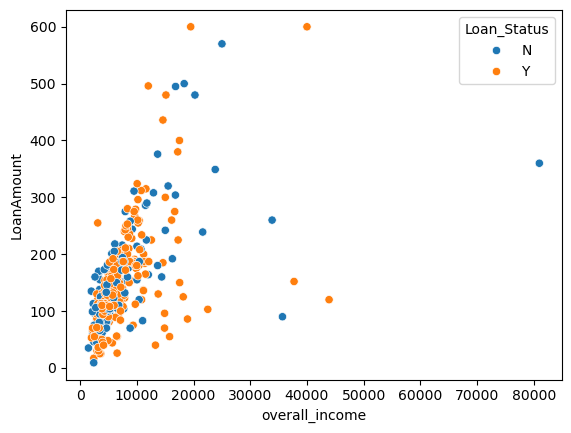

In [37]:
sns.scatterplot(x=df['overall_income'],y=df['LoanAmount'],hue=df['Loan_Status'])

<Axes: xlabel='Credit_History', ylabel='overall_income'>

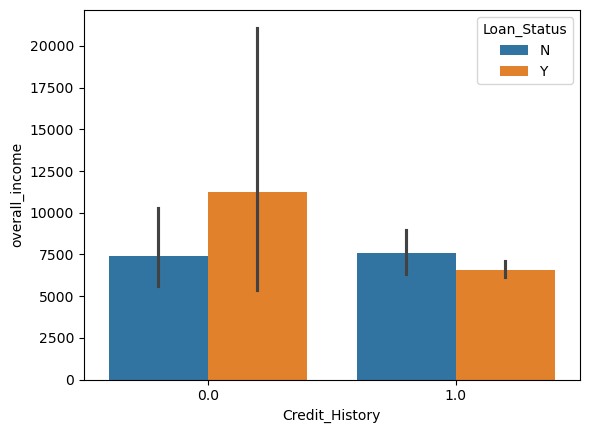

In [38]:
sns.barplot(x=df["Credit_History"],y=df['overall_income'],hue=df['Loan_Status'])

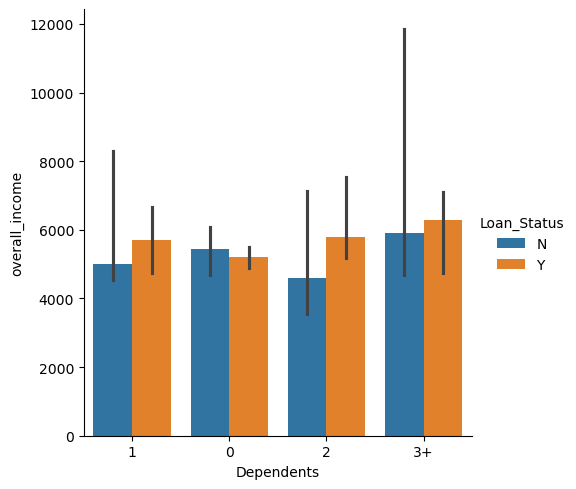

In [39]:
sns.catplot(x=df["Dependents"],y=df['overall_income'],hue=df['Loan_Status'],estimator='median',kind='bar')

In [40]:
pd.crosstab(df['Loan_Status'],df['Gender'],normalize=True)

Gender,Female,Male
Loan_Status,,
N,0.066667,0.241667
Y,0.112500,0.579167


In [ ]:
#The End